# Step 3 · Pair-season statistics and the pilot check

Runs after `data.ipynb` (builds the teammate gaps) and `analysis.ipynb` (EDA).

**Input:** `data/teammate_gaps.csv` · **Output:** `data/pair_seasons.csv`, `data/teammate_gaps_flagged.csv`, `figures/forest_2025_2026.png`

What this notebook does:
1. Flags outliers with the 1.5 × IQR rule within each pair-season (Eq. 2).
2. Summarises every pair-season: mean, median, SD, 95% t-interval (Eq. 3), head-to-head, proportion CI and chi-square CI for the SD.
3. Estimates τ², the season-to-season drift of a pair's gap, used by every chain (Eq. 4).
4. Recomputes the pilot check (report Table 3) from the real data.

The reusable functions are in `f1_stats.py`, next to this notebook.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from f1_stats import (load_gaps, pair_season_table, pair_gap, estimate_tau2, chain,
                      setup_plot_style, short, MIN_SESSIONS, BLUE, MUTED)

setup_plot_style()
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

gaps = load_gaps()          # teammate_gaps.csv plus an 'outlier' column (Eq. 2)
print(len(gaps), 'teammate comparisons')

2655 teammate comparisons


## 1. Outliers (Eq. 2)

A session is an outlier if its gap is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR **of that pair-season**. Outliers are flagged, not deleted: they are left out of the mean but kept in the median and the head-to-head count.

In [2]:
n_out = gaps['outlier'].sum()
print(f'{n_out} of {len(gaps)} sessions flagged as outliers ({n_out / len(gaps):.1%})')
print(f"Skewness, all gaps:         {stats.skew(gaps['gap']):.2f}")
print(f"Skewness, outliers removed: {stats.skew(gaps.loc[~gaps['outlier'], 'gap']):.2f}")

# The most extreme sessions (for the hand review in the report)
gaps.loc[gaps['gap'].abs().nlargest(5).index,
         ['year', 'round', 'team', 'A', 'B', 'segment', 'gap']].round(2)

210 of 2655 sessions flagged as outliers (7.9%)
Skewness, all gaps:         -0.84
Skewness, outliers removed: -0.21


,year,round,team,A,B,segment,gap
1880,2023,9,red-bull,max-verstappen,sergio-perez,Q2,-48.73
1424,2021,7,aston-martin,lance-stroll,sebastian-vettel,Q1,43.91
1812,2023,2,williams,alexander-albon,logan-sargeant,Q1,-29.97
1562,2021,21,ferrari,carlos-sainz-jr,charles-leclerc,Q2,28.48
1811,2023,2,red-bull,max-verstappen,sergio-perez,Q2,24.05


## 2. Pair-season summary (Eq. 3)

One row per pair per season. Columns:
- `sessions`, `outliers`, `n` — all sessions, flagged ones, and the clean sessions used for the mean
- `mean`, `sd`, `se` — of the clean gaps; `median` uses all sessions
- `ci_low`, `ci_high`, `margin` — 95% t-interval: mean ± t(0.975, n−1) · s/√n
- `a_wins`, `b_wins` — head-to-head; `p_low`/`p_high` — proportion CI, only when n·p̂(1−p̂) > 5
- `sd_low`, `sd_high` — chi-square CI for the SD: how consistent the pair is
- `usable` — at least 8 sessions (report Table 4); `significant` — the CI excludes 0

Sign convention: driver **A** is the alphabetically first `driverId`, and a negative gap means A was faster.

In [3]:
ps = pair_season_table(gaps)
usable = ps[ps['usable']]

print(f'{len(ps)} pair-seasons, {len(usable)} with at least {MIN_SESSIONS} sessions')
print(f"Median margin of error (half-width of the 95% CI): ±{usable['margin'].median():.2f} "
      f"(middle half of pairs: ±{usable['margin'].quantile(0.25):.2f} to ±{usable['margin'].quantile(0.75):.2f})")
print(f"{usable['significant'].sum()} of {len(usable)} pair-seasons have a CI that excludes 0")
print(f"Proportion CI allowed (n·p̂(1−p̂) > 5) for {usable['p_low'].notna().sum()} pair-seasons")

170 pair-seasons, 137 with at least 8 sessions
Median margin of error (half-width of the 95% CI): ±0.19 (middle half of pairs: ±0.16 to ±0.26)
71 of 137 pair-seasons have a CI that excludes 0
Proportion CI allowed (n·p̂(1−p̂) > 5) for 18 pair-seasons


In [4]:
cols = ['year', 'team', 'A', 'B', 'sessions', 'outliers', 'mean', 'ci_low', 'ci_high',
        'median', 'sd', 'sd_low', 'sd_high', 'a_wins', 'b_wins']
usable[usable['year'] == 2025][cols].round(3)

,year,team,A,B,sessions,outliers,mean,ci_low,ci_high,median,sd,sd_low,sd_high,a_wins,b_wins
144,2025,alpine,franco-colapinto,pierre-gasly,18,1,0.286,0.047,0.525,0.383,0.464,0.346,0.707,5,13
146,2025,aston-martin,fernando-alonso,lance-stroll,23,0,-0.472,-0.631,-0.312,-0.363,0.368,0.285,0.521,23,0
147,2025,ferrari,charles-leclerc,lewis-hamilton,24,1,-0.219,-0.327,-0.112,-0.245,0.249,0.193,0.352,19,5
148,2025,haas,esteban-ocon,oliver-bearman,22,1,0.170,0.004,0.335,0.199,0.364,0.278,0.525,9,13
149,2025,kick-sauber,gabriel-bortoleto,nico-hulkenberg,23,2,-0.084,-0.226,0.057,-0.082,0.310,0.237,0.448,12,11
150,2025,mclaren,lando-norris,oscar-piastri,24,5,-0.032,-0.132,0.068,-0.036,0.208,0.157,0.307,14,10
151,2025,mercedes,george-russell,kimi-antonelli,24,4,-0.376,-0.483,-0.270,-0.384,0.227,0.173,0.332,21,3
152,2025,racing-bulls,isack-hadjar,liam-lawson,21,2,-0.166,-0.306,-0.027,-0.165,0.290,0.219,0.429,16,5
155,2025,red-bull,max-verstappen,yuki-tsunoda,21,1,-0.646,-0.769,-0.524,-0.718,0.261,0.199,0.382,21,0
156,2025,williams,alexander-albon,carlos-sainz-jr,23,0,0.117,-0.125,0.359,0.097,0.559,0.432,0.791,9,14


## 3. τ²: how much a pair's gap changes from one season to the next

For a pair seen in seasons s and s+1, the change d = g(s+1) − g(s) has variance SE(s)² + SE(s+1)² + τ². So

  τ² = mean of [ d² − SE(s)² − SE(s+1)² ]

This is the τ² in Eq. 4: a chain link from m seasons away adds m·τ² to the variance.

In [5]:
tau2, consecutive = estimate_tau2(ps)
print(f'tau^2 = {tau2:.4f}  (from {len(consecutive)} pairs seen in consecutive seasons)')
print(f'The progress report used a pilot value of 0.0085; the data give {tau2:.4f}.')

tau^2 = 0.0153  (from 61 pairs seen in consecutive seasons)
The progress report used a pilot value of 0.0085; the data give 0.0153.


## 4. Pilot check (report Table 3), recomputed

`pair_gap(ps, year, a, b)` returns the gap written as *a minus b*, so the table reads the same way as the report.
The chain uses Eq. 4: Antonelli–Hamilton = (Antonelli–Russell, 2025) + (Russell–Hamilton, 2024), which crosses one season (m = 1).

In [6]:
def h2h(a, b, p):
    winner, loser = (a, b) if p['wins_a'] >= p['wins_b'] else (b, a)
    return f"{short(winner)} {max(p['wins_a'], p['wins_b'])}–{min(p['wins_a'], p['wins_b'])}"

ant_rus_25 = pair_gap(usable, 2025, 'kimi-antonelli', 'george-russell')
rus_ham_24 = pair_gap(usable, 2024, 'george-russell', 'lewis-hamilton')
ant_rus_26 = pair_gap(usable, 2026, 'kimi-antonelli', 'george-russell')

g, se_plain, se_drift = chain([(ant_rus_25['mean'], ant_rus_25['se']),
                               (rus_ham_24['mean'], rus_ham_24['se'])],
                              seasons_crossed=1, tau2=tau2)
z = stats.norm.ppf(0.975)

pilot = pd.DataFrame([
    ['Antonelli vs Russell 2025', ant_rus_25['mean'], ant_rus_25['ci_low'], ant_rus_25['ci_high'],
     h2h('kimi-antonelli', 'george-russell', ant_rus_25)],
    ['Russell vs Hamilton 2024', rus_ham_24['mean'], rus_ham_24['ci_low'], rus_ham_24['ci_high'],
     h2h('george-russell', 'lewis-hamilton', rus_ham_24)],
    ['Antonelli vs Hamilton (chain, no drift)', g, g - z * se_plain, g + z * se_plain, '–'],
    ['Antonelli vs Hamilton (chain, with tau^2)', g, g - z * se_drift, g + z * se_drift, '–'],
    ['Antonelli vs Russell 2026', ant_rus_26['mean'], ant_rus_26['ci_low'], ant_rus_26['ci_high'],
     h2h('kimi-antonelli', 'george-russell', ant_rus_26)],
], columns=['comparison', 'mean gap %', 'CI low', 'CI high', 'head-to-head'])
pilot.round(2)

,comparison,mean gap %,CI low,CI high,head-to-head
0,Antonelli vs Russell 2025,0.38,0.27,0.48,Russell 21–3
1,Russell vs Hamilton 2024,-0.21,-0.33,-0.10,Russell 19–5
2,"Antonelli vs Hamilton (chain, no drift)",0.16,0.01,0.31,–
3,"Antonelli vs Hamilton (chain, with tau^2)",0.16,-0.12,0.45,–
4,Antonelli vs Russell 2026,-0.12,-0.31,0.06,Antonelli 10–7


## 5. Forest plot: every 2025 and 2026 pair with its 95% CI
Filled dot = the CI excludes 0 (one driver is genuinely faster); hollow dot = too close to call.

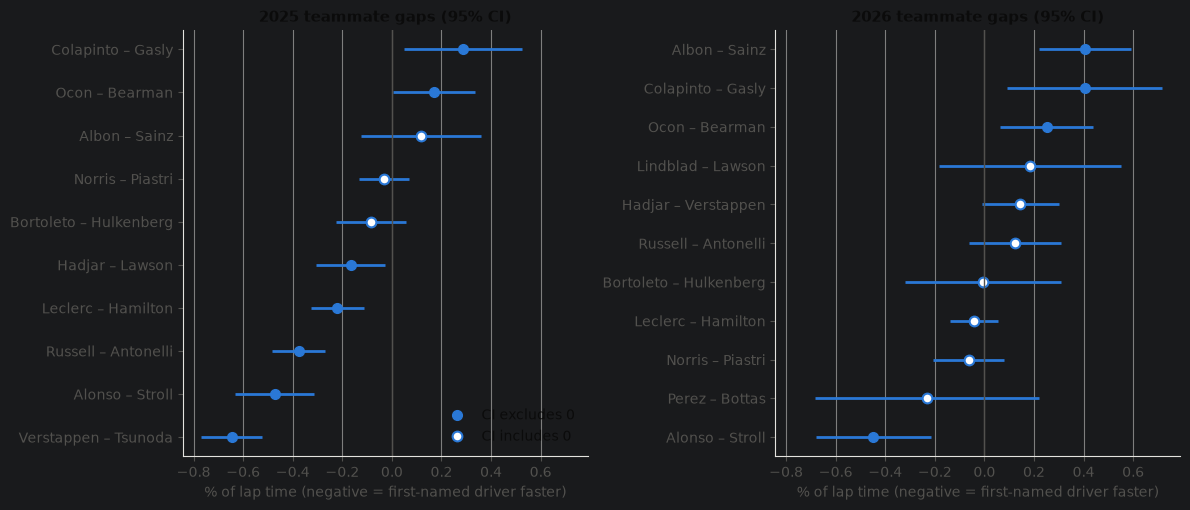

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
for ax, year in zip(axes, [2025, 2026]):
    d = usable[usable['year'] == year].sort_values('mean').reset_index(drop=True)
    y = np.arange(len(d))
    sig = d['significant'].to_numpy()
    ax.hlines(y, d['ci_low'], d['ci_high'], color=BLUE, linewidth=2)
    ax.plot(d.loc[sig, 'mean'], y[sig], 'o', color=BLUE, markersize=7, label='CI excludes 0')
    ax.plot(d.loc[~sig, 'mean'], y[~sig], 'o', color=BLUE, markerfacecolor='white',
            markeredgewidth=1.5, markersize=7, label='CI includes 0')
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y, [f'{short(a)} – {short(b)}' for a, b in zip(d['A'], d['B'])])
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{year} teammate gaps (95% CI)')
    ax.set_xlabel('% of lap time (negative = first-named driver faster)')
axes[0].legend(loc='lower right')
fig.tight_layout()
fig.savefig('figures/forest_2025_2026.png', bbox_inches='tight')
plt.show()

## 6. Save

In [8]:
ps.to_csv('data/pair_seasons.csv', index=False)
gaps.to_csv('data/teammate_gaps_flagged.csv', index=False)
print('saved data/pair_seasons.csv and data/teammate_gaps_flagged.csv')

saved data/pair_seasons.csv and data/teammate_gaps_flagged.csv
